# A7 — Quantum Cryptography: Simulate BB84 (Quantum Key Distribution)

Vivekananda GN

Alice sends qubits; Bob measures; they keep results where their bases matched. An eavesdropper (Eve) disturbs the qubits and creates errors.
This is **QKD** (physics-based key exchange). It is *not* machine learning and *not* post-quantum cryptography.
lab.quantumflytrap.com/lab/bb84

In [ ]:
# Run once (Google Colab or local). Qibo is an open-source quantum framework: https://qibo.science
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.2 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")           # plain CPU simulator, works everywhere
np.set_printoptions(precision=3, suppress=True)

[Qibo 0.3.5|INFO|2026-10-03 04:57:51]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


## 5.1 One photon through the protocol
* Alice: random bit, random basis (0 = Z, 1 = X). Prepare |bit>, apply H if basis = 1.
* Eve (optional): measure in a random basis and resend (intercept-resend).
* Bob: random basis, apply H if basis = 1, measure.

In [ ]:
rng = np.random.default_rng(7)

def send_photon(bit, a_basis, b_basis, e_basis=None):
    c = Circuit(1)
    if bit: c.add(gates.X(0))
    if a_basis: c.add(gates.H(0))
    if e_basis is not None:                     # Eve intercepts, measures, resends in her basis
        if e_basis: c.add(gates.H(0))
        c.add(gates.M(0, collapse=True))
        if e_basis: c.add(gates.H(0))
    if b_basis: c.add(gates.H(0))
    c.add(gates.M(0))
    return int(list(c(nshots=1).frequencies().keys())[0])

def run_bb84(n=400, eve_fraction=0.0, seed=0):
    r = np.random.default_rng(seed)
    bits, ab, bb = r.integers(0, 2, n), r.integers(0, 2, n), r.integers(0, 2, n)
    eve_on = r.random(n) < eve_fraction; eb = r.integers(0, 2, n)
    bob = np.array([send_photon(bits[i], ab[i], bb[i], eb[i] if eve_on[i] else None) for i in range(n)])
    keep = ab == bb                                        # publicly compare bases only
    sifted_alice, sifted_bob = bits[keep], bob[keep]
    qber = np.mean(sifted_alice != sifted_bob)
    return keep.sum(), qber

for eve in [0.0, 1.0]:
    k, q = run_bb84(eve_fraction=eve)
    print(f"Eve intercepts {int(eve*100):>3}% of photons -> sifted key length = {k}, error rate (QBER) = {q:.1%}")

Eve intercepts   0% of photons -> sifted key length = 193, error rate (QBER) = 0.0%
Eve intercepts 100% of photons -> sifted key length = 193, error rate (QBER) = 25.9%


**Result to look for:** No Eve → QBER ≈ 0%. Eve intercepting everything → QBER ≈ 25%. Alice and Bob detect her by sacrificing a sample of the key and checking errors.

## 5.2 How much eavesdropping can we detect?

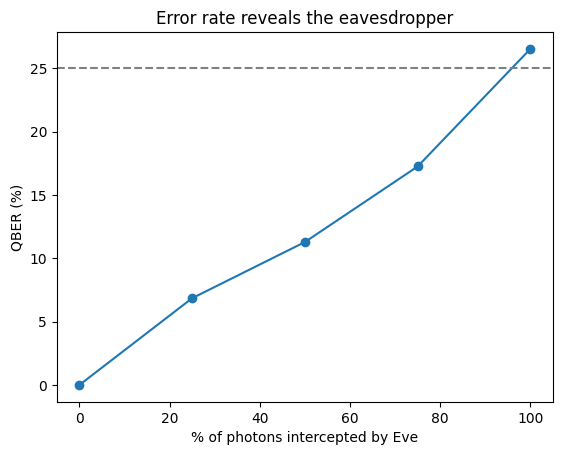

In [ ]:
fr = [0, 0.25, 0.5, 0.75, 1.0]
q = [np.mean([run_bb84(600, f, seed=s)[1] for s in range(3)]) for f in fr]
plt.plot([f*100 for f in fr], [x*100 for x in q], 'o-'); plt.axhline(25, ls='--', c='gray')
plt.xlabel('% of photons intercepted by Eve'); plt.ylabel('QBER (%)'); plt.title('Error rate reveals the eavesdropper'); plt.show()

## 5.3 Discussion
1. Why can Eve not simply copy the qubit? (No-cloning theorem.)
2. Which part of cryptography does this *not* cover? (Encryption of the message, digital signatures, and today's internet traffic still relies on classical algorithms such as the new NIST post-quantum standards.)
3. Where could ML/QML help around QKD? (Anomaly detection on error rates, hardware tuning, security analysis of quantum models — all research-stage.)